# T3: First-order differentiable architecture search
Six edges connect all pairs $i<j$ in a four-node DAG. Each edge computes
$\bar o(x)=\sum_o\mathrm{softmax}(\alpha)_o o(x)$, and each node sums its inputs.
The two cells share $\alpha\in\mathbb{R}^{6\times5}$ but have separate weights.


In [ ]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "code"))


**Latency note:** Timings printed in the training cells are provisional. The final report and analysis below use the controlled comparison in `reprofile.ipynb`, which reloads the saved checkpoints and times them together after training.

In [1]:
from common import *

seed_all(43)
train, val = cifar_data(43)
EDGES = [(i, j) for j in range(1, 4) for i in range(j)]
OPS = ["none", "skip", "conv1x1", "conv3x3", "avgpool3x3"]


Generating test split: 100%|##########| 10000/10000 [00:00<00:00, 232634.33 examples/s]


## Operations and continuous network
GroupNorm has no running statistics, so freezing weights during architecture
updates also avoids any hidden BatchNorm-buffer updates.


In [2]:
class Zero(nn.Module):
    def forward(self, x):
        return x * 0


def operation(index):
    if index == 0:
        return Zero()
    if index == 1:
        return nn.Identity()
    if index == 4:
        return nn.AvgPool2d(3, 1, 1, count_include_pad=False)
    kernel = 1 if index == 2 else 3
    return nn.Sequential(
        nn.Conv2d(16, 16, kernel, padding=kernel // 2, bias=False),
        nn.GroupNorm(4, 16),
        nn.ReLU(),
    )


class Cell(nn.Module):
    def __init__(self):
        super().__init__()
        self.edges = nn.ModuleList(
            [nn.ModuleList([operation(k) for k in range(5)]) for _ in EDGES]
        )

    def forward(self, x, prob):
        nodes = [x]
        for j in range(1, 4):
            terms = []
            for edge, (i, dest) in enumerate(EDGES):
                if dest == j:
                    terms.append(
                        sum(
                            p * op(nodes[i])
                            for p, op in zip(prob[edge], self.edges[edge])
                        )
                    )
            nodes.append(sum(terms))
        return nodes[3]


class Supernet(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Conv2d(3, 16, 3, padding=1)
        self.cells = nn.ModuleList([Cell(), Cell()])
        self.head = nn.Linear(16, 10)
        self.alpha = nn.Parameter(torch.zeros(6, 5))

    def forward(self, x):
        x = self.stem(x)
        for cell in self.cells:
            x = cell(x, self.alpha.softmax(-1))
        return self.head(x.mean((2, 3)))


model = Supernet().to(DEVICE)
weights = [p for n, p in model.named_parameters() if n != "alpha"]
x, y = next(iter(loader(train)))
x, y = x.to(DEVICE), y.to(DEVICE)
before = model(x).detach()
F.cross_entropy(model(x), y).backward()
checks = {
    "output_shape": list(before.shape),
    "alpha_shape": list(model.alpha.shape),
    "probability_sums": model.alpha.softmax(-1).sum(-1).tolist(),
    "alpha_gradient_nonzero": bool(model.alpha.grad.abs().sum() > 0),
    "separate_cell_weights": model.cells[0].edges[0][2][0].weight.data_ptr()
    != model.cells[1].edges[0][2][0].weight.data_ptr(),
}
with torch.no_grad():
    model.alpha[:, 1] = 2
checks["alpha_changes_output"] = not torch.allclose(before, model(x))
with torch.no_grad():
    model.alpha.zero_()
model.zero_grad(set_to_none=True)
print(checks)


{'output_shape': [64, 10], 'alpha_shape': [6, 5], 'probability_sums': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 'alpha_gradient_nonzero': True, 'separate_cell_weights': True, 'alpha_changes_output': True}


## Alternating first-order updates: three epochs
Training batches update only $w$. Validation batches update only $\alpha$,
without unrolling or differentiating through the weight optimizer.


In [3]:
wopt = torch.optim.Adam(weights, lr=0.001)
aopt = torch.optim.Adam([model.alpha], lr=0.003)
history = []
probabilities = [model.alpha.softmax(-1).detach().cpu().tolist()]
tr_loader = loader(train, True, 43)
va_loader = loader(val, True, 44)
sync()
start = time.perf_counter()
for epoch in range(3):
    model.train()
    va_iter = iter(va_loader)
    total = correct = count = 0
    for step, (x, y) in enumerate(tr_loader):
        x, y = x.to(DEVICE), y.to(DEVICE)
        alpha_before = model.alpha.detach().clone()
        w_before = [p.detach().clone() for p in weights] if epoch == step == 0 else None
        model.alpha.requires_grad_(False)
        wopt.zero_grad(set_to_none=True)
        z = model(x)
        loss = F.cross_entropy(z, y)
        loss.backward()
        wopt.step()
        if epoch == step == 0:
            checks["weight_step_alpha_unchanged"] = torch.equal(
                alpha_before, model.alpha
            )
            checks["weight_step_weights_changed"] = any(
                not torch.equal(a, b) for a, b in zip(w_before, weights)
            )
        total += loss.item() * len(y)
        correct += (z.argmax(1) == y).sum().item()
        count += len(y)
        try:
            vx, vy = next(va_iter)
        except StopIteration:
            va_iter = iter(va_loader)
            vx, vy = next(va_iter)
        for p in weights:
            p.requires_grad_(False)
        model.alpha.requires_grad_(True)
        w_before = [p.detach().clone() for p in weights] if epoch == step == 0 else None
        aopt.zero_grad(set_to_none=True)
        F.cross_entropy(model(vx.to(DEVICE)), vy.to(DEVICE)).backward()
        aopt.step()
        if epoch == step == 0:
            checks["alpha_step_weights_unchanged"] = all(
                torch.equal(a, b) for a, b in zip(w_before, weights)
            )
            checks["alpha_step_alpha_changed"] = not torch.equal(
                alpha_before, model.alpha
            )
        for p in weights:
            p.requires_grad_(True)
    history.append(
        {
            "epoch": epoch + 1,
            "train": {"loss": total / count, "accuracy": 100 * correct / count},
            "validation": evaluate(model, loader(val)),
        }
    )
    probabilities.append(model.alpha.softmax(-1).detach().cpu().tolist())
    print(history[-1], flush=True)
sync()
search = {
    "history": history,
    "seconds": time.perf_counter() - start,
    "weight_updates": 3 * len(tr_loader),
    "alpha_updates": 3 * len(tr_loader),
}
torch.save(model.state_dict(), ROOT / "checkpoints" / "t3_supernet.pt")


{'epoch': 1, 'train': {'loss': 2.2235373596191406, 'accuracy': 17.94}, 'validation': {'loss': 2.1180591049194337, 'accuracy': 21.3}}
{'epoch': 2, 'train': {'loss': 2.0538471435546874, 'accuracy': 24.22}, 'validation': {'loss': 1.9955509033203125, 'accuracy': 24.0}}
{'epoch': 3, 'train': {'loss': 1.9611349849700928, 'accuracy': 26.44}, 'validation': {'loss': 1.9409643630981446, 'accuracy': 26.0}}


## Discretize the same checkpoint, then train a fresh copy
For each node retain its two strongest incoming edges (one for node 1),
ranked by maximum non-zero probability. No adaptation precedes evaluation.


In [4]:
prob = model.alpha.softmax(-1).detach().cpu()
encoding = []
for j in range(1, 4):
    incoming = [e for e, (i, d) in enumerate(EDGES) if d == j]
    retained = sorted(incoming, key=lambda e: float(prob[e, 1:].max()), reverse=True)[
        :2
    ]
    encoding.extend((e, int(prob[e, 1:].argmax()) + 1) for e in retained)
assert len(encoding) == 5


class Discrete(nn.Module):
    def __init__(self, source):
        super().__init__()
        self.stem = copy.deepcopy(source.stem)
        self.cells = nn.ModuleList(
            [
                nn.ModuleDict(
                    {str(e): copy.deepcopy(c.edges[e][o]) for e, o in encoding}
                )
                for c in source.cells
            ]
        )
        self.head = copy.deepcopy(source.head)

    def forward(self, x):
        x = self.stem(x)
        for cell in self.cells:
            nodes = [x]
            for j in range(1, 4):
                nodes.append(
                    sum(
                        cell[str(e)](nodes[EDGES[e][0]])
                        for e, o in encoding
                        if EDGES[e][1] == j
                    )
                )
            x = nodes[3]
        return self.head(x.mean((2, 3)))


inherited = Discrete(model).to(DEVICE)
comparison = {}
for name, net in [("continuous", model), ("inherited", inherited)]:
    comparison[name] = {**evaluate(net, loader(val)), **profile(net)}
seed_all(43)
scratch = Discrete(Supernet()).to(DEVICE)
scratch_run = fit(scratch, train, val, 5, 43)
comparison["scratch"] = {**evaluate(scratch, loader(val)), **profile(scratch)}
torch.save(scratch.state_dict(), ROOT / "checkpoints" / "t3_scratch.pt")
result = {
    "checks": checks,
    "search": search,
    "probabilities": probabilities,
    "edges": EDGES,
    "operations": OPS,
    "encoding": encoding,
    "comparison": comparison,
    "scratch": scratch_run,
}
save_json("task3", result)
print(comparison)


{'epoch': 1, 'train': {'loss': 2.1951875801086427, 'accuracy': 19.42}, 'validation': {'loss': 2.090433120727539, 'accuracy': 21.3}}
{'epoch': 2, 'train': {'loss': 2.0466567626953127, 'accuracy': 25.04}, 'validation': {'loss': 2.013591003417969, 'accuracy': 24.7}}
{'epoch': 3, 'train': {'loss': 1.9886382415771484, 'accuracy': 26.26}, 'validation': {'loss': 1.9650171966552734, 'accuracy': 28.6}}
{'epoch': 4, 'train': {'loss': 1.9466869857788085, 'accuracy': 28.86}, 'validation': {'loss': 1.944131088256836, 'accuracy': 27.6}}
{'epoch': 5, 'train': {'loss': 1.9123609558105468, 'accuracy': 30.6}, 'validation': {'loss': 1.8947798461914063, 'accuracy': 29.9}}
{'continuous': {'loss': 1.9409643630981446, 'accuracy': 26.0, 'parameters': 32136, 'macs': 31899808, 'size_mib': 0.122589111328125, 'latency_ms': 4.613149999954658, 'timings_ms': [4.549699999870427, 4.525800000010349, 6.151000000045315, 4.605599999877086, 4.374699999971199, 4.62070000003223, 4.88830000017515, 4.514100000051258, 4.5251000

## Curves and cell graphs


In [5]:
curves({"Search": search, "Discrete scratch": scratch_run}, "t3_training")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, e in zip(axes, [0, 5]):
    for k, op in enumerate(OPS):
        ax.plot(range(4), np.array(probabilities)[:, e, k], label=op)
    ax.set(
        title=f"Edge {EDGES[e]}", xlabel="Search epoch", ylabel="Operation probability"
    )
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(ROOT / "figures" / "t3_probabilities.png", dpi=150)
plt.close(fig)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
positions = {0: (0, 0), 1: (1, 1), 2: (2, 1), 3: (3, 0)}
for ax, title, graph in [
    (axes[0], "Continuous cell", [(e, None) for e in range(6)]),
    (axes[1], "Extracted cell", encoding),
]:
    for e, o in graph:
        i, j = EDGES[e]
        a, b = positions[i], positions[j]
        ax.annotate(
            "",
            xy=b,
            xytext=a,
            arrowprops={
                "arrowstyle": "->",
                "connectionstyle": "arc3,rad=0.12",
                "shrinkA": 12,
                "shrinkB": 12,
            },
        )
        ax.text(
            (a[0] + b[0]) / 2,
            (a[1] + b[1]) / 2 - 0.12,
            "mixed" if o is None else OPS[o],
            fontsize=7,
        )
    for n, (a, b) in positions.items():
        ax.text(
            a,
            b,
            str(n),
            bbox={"boxstyle": "circle", "facecolor": "lightblue"},
            ha="center",
            va="center",
        )
    ax.set(xlim=(-0.3, 3.3), ylim=(-0.6, 1.4), title=title)
    ax.axis("off")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "t3_graphs.png", dpi=150)
plt.close(fig)


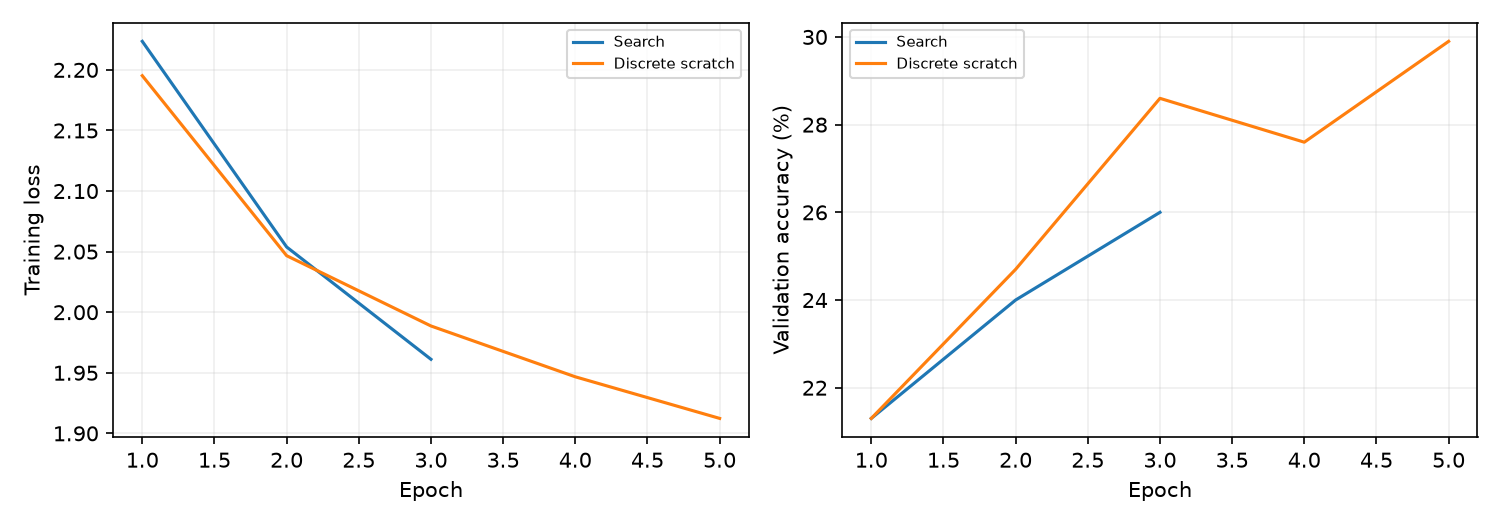

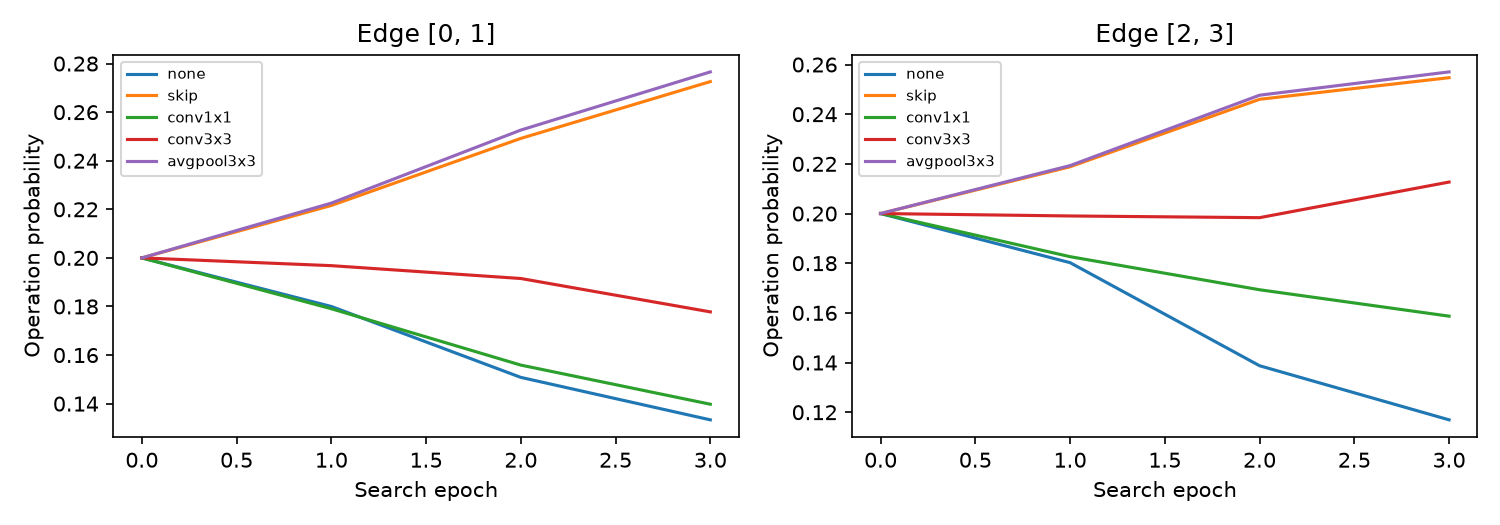

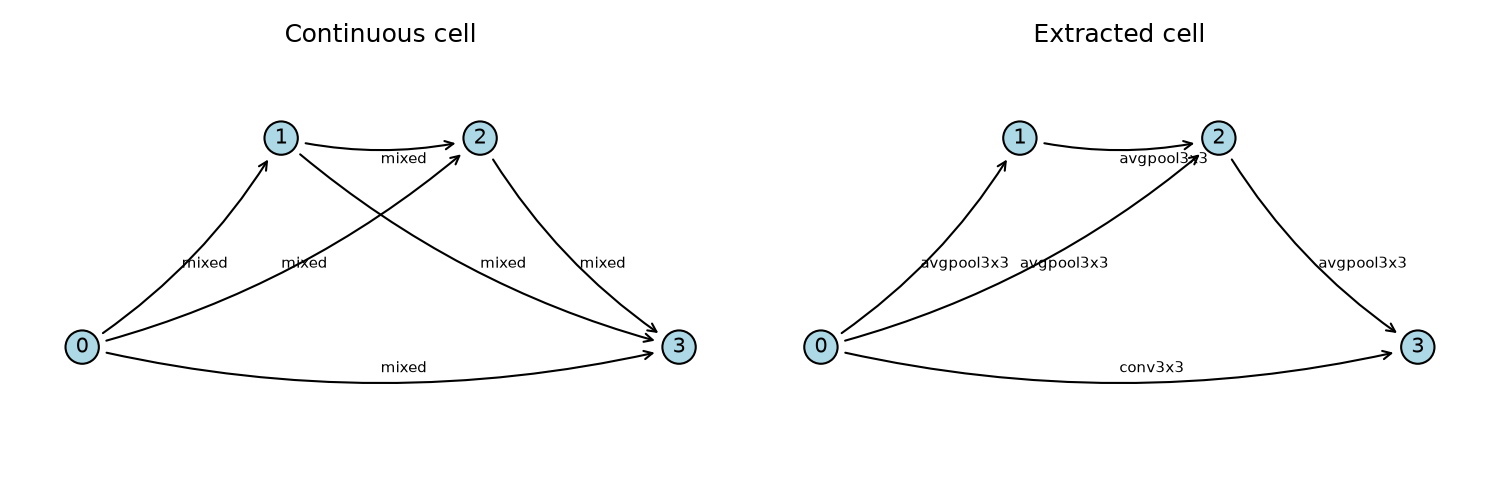

In [ ]:
from IPython.display import Image, display

display(Image(filename=str(project_root / "figures" / "t3_training.png")))
display(Image(filename=str(project_root / "figures" / "t3_probabilities.png")))
display(Image(filename=str(project_root / "figures" / "t3_graphs.png")))


# Analysis

## T3.1: Differentiable Cell

**Q1.** Show the cell graph, architecture parameter dimensions, and verification results. Explain why the architecture parameters can be optimized using gradients.

**Answer:**


![Continuous four-node cell (six edges) and the extracted five-edge architecture; both networks contain two cells.](../figures/t3_graphs.png)

Continuous four-node cell (six edges) and the extracted five-edge architecture; both networks contain two cells.
Each cell connects (0,1), (0,2), (1,2), (0,3), (1,3), (2,3). Candidates are none, skip, 1 x 1 convolution, 3 x 3 convolution, and 3 x 3 average pooling. Convolutional candidates use GroupNorm and ReLU. All operations preserve 16 channels and 32 x 32 resolution. The fixed 3 x 3 stem is followed by two searchable cells, global average pooling and a 10-class linear head.

$$p_{e,o}=\frac{e^{\alpha_{e,o}}}{\sum_{o'}e^{\alpha_{e,o'}}},\qquad x_j=\sum_{i<j}\sum_o p_{(i,j),o}\,o(x_i).$$

There is one shared architecture tensor of shape 6 x 5 (30 parameters). The cells own separate operation weights. Softmax and weighted sums are differentiable, so cross-entropy gradients reach the architecture parameters via the mixture coefficients. No discrete sampling occurs during continuous search.

| Verification | Observed value |
| --- | --- |
| output_shape | [64, 10] |
| alpha_shape | [6, 5] |
| probability_sums | [1.0, 1.0, 1.0, 1.0, 1.0, 1.0] |
| alpha_gradient_nonzero | True |
| separate_cell_weights | True |
| alpha_changes_output | True |


## T3.2: First-Order Search

**Q1.** Show parameter-update verification, training curves, and probability histories for at least two edges. Which operations became more likely during search?

**Answer:**

| Optimizer verification | Passed |
| --- | --- |
| weight_step_alpha_unchanged | True |
| weight_step_weights_changed | True |
| alpha_step_weights_unchanged | True |
| alpha_step_alpha_changed | True |
The seed-43 CIFAR-10 split contains exactly 500 training and 100 validation images per class, with no overlap. Inputs use fixed normalization and no random augmentation. Batch size is 64. Adam updates network weights at learning rate 0.001 using training batches; a separate Adam updates alpha at 0.003 using validation batches. Weight gradients are disabled for the architecture step and alpha gradients are disabled for the weight step. GroupNorm has no mutable running statistics. The validation iterator cycles as needed.

Three epochs performed 237 weight updates and 237 architecture updates, taking 58.98 s including epoch validation. This is first-order optimization; it does not differentiate through the weight update.

![Training losses and validation accuracy for the search and fresh discrete network.](../figures/t3_training.png)

Training losses and validation accuracy for the search and fresh discrete network.

![Probability histories for edges (0,1) and (2,3), including the uniform initialization.](../figures/t3_probabilities.png)

Probability histories for edges (0,1) and (2,3), including the uniform initialization.
Final highest-probability operations by edge: (0, 1): avgpool3x3 (0.277), (0, 2): avgpool3x3 (0.281), (1, 2): avgpool3x3 (0.248), (0, 3): conv3x3 (0.249), (1, 3): avgpool3x3 (0.227), (2, 3): avgpool3x3 (0.257).


## T3.3: Extract and Evaluate a Discrete Architecture

**Q1.** Compare the continuous supernet, inherited-weight model, and independently trained model. How much did performance change after discretization and independent training?

**Answer:**

| Model | Validation accuracy (%) | Parameters | Conv/linear MACs | Tensor size (MiB) | Median latency (ms) |
| --- | --- | --- | --- | --- | --- |
| Continuous supernet | 26.00 | 32136 | 31899808 | 0.12 | 5.35 |
| Discrete: inherited | 21.60 | 5290 | 5161120 | 0.02 | 0.71 |
| Discrete: scratch | 29.90 | 5290 | 5161120 | 0.02 | 0.66 |
Encoding: (0, 1) = avgpool3x3, (0, 2) = avgpool3x3, (1, 2) = avgpool3x3, (2, 3) = avgpool3x3, (0, 3) = conv3x3.

For each node we ranked incoming edges by their largest non-none probability, retained up to two, and selected the corresponding non-none operation. The five-edge architecture is shown above. The continuous and inherited models were evaluated from the same saved search checkpoint with no intervening fine-tuning. Discretization changed validation accuracy by -4.40 percentage points. Fresh initialization and five epochs (395 updates) changed it by +8.30 points relative to inherited weights. Scratch training took 12.61 s.

Parameters and MACs are analytical counts; latency is measured. MACs count convolution and linear multiply-accumulates only, excluding pooling, normalization, activations, softmax and mixture arithmetic. Tensor size counts serialized state tensors, excluding file-container overhead. Inherited and scratch models have the same computational graph; their latency difference is measurement/runtime variability, not an architectural change.
